A box with a cone jutting out of it. The MCNP guide recommends taking the cone as its own region, then unioning it with the rest of the box to form the desired cell. The same strategy works in OpenMC.

In [1]:
import openmc as omc

# Surface definitions
# equivalent to MCNP's macrobody BOX
s1 = omc.model.OrthogonalBox((-2.5,-2.5,0), (5, 0, 0), (0, 5, 0), (0, 0, 5))  
#print(s1.component_surfaces)
# openmc.ZCone has both sides; openmc.ZConeOneSided may be preferable for MCNP kz card.
s2 = omc.model.ZConeOneSided(z0=8,r2= 0.25,up=False) 

&: intersection, logical AND, (MCNP's ' ')
|: union, logical OR, (MCNP's ':')
~: complement, logical NOT, (MCNP's '#')

In [2]:
# Cell definitions
c1 = omc.Cell(cell_id=1,fill=None,region= (-s1 | (-s2 & +s1.component_surfaces[5]))) 
              # the s1.component_surfaces[4] is equivalent to the ".5" macrobody surface as in MCNP
              # numbering goes as [-xmin, xmax, -ymin, ymax, -zmin, zmax] at least if 
              # oriented along axes and defined with vectors as they are
c2 = omc.Cell(cell_id=2,fill=None,region=~c1.region)
geometry=omc.Geometry([c1, c2])
#print(geometry.get_all_surfaces())
geometry.export_to_xml()

In [4]:
material=omc.Materials()
material.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'
material.export_to_xml()

setting = omc.Settings()
setting.export_to_xml()

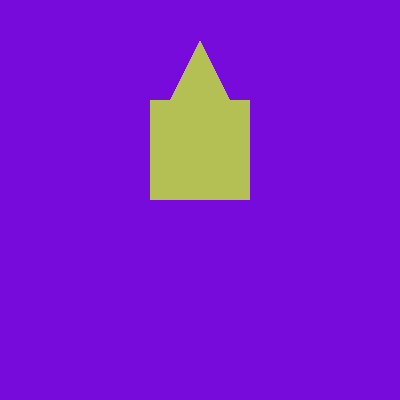

In [3]:
plot = omc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (20., 20.)
plot.pixels = (400, 400)
plot.color_by= 'cell'
plots = omc.Plots([plot])
omc.plot_inline(plots)